In [3]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [4]:
API_KEY = "***REMOVED***"

dna_model = dna_client.create(API_KEY)

In [5]:
from pyliftover import LiftOver
lo = LiftOver('hg19', 'hg38')
def to_variant(snp):
    c, p, ref, alt = snp.split('_')
    hit = lo.convert_coordinate(f'chr{c}', int(p) - 1)   # assumes 1-based ids
    return genome.Variant(f'chr{c}', hit[0][1] + 1, ref, alt, name=snp)


In [6]:
Z_SCORES = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv")
Z_SCORES

,SNP,Lumsec_major,CD4_naive,Vas_arterial,T_prol,Lymph_valve2,Vas_venous,pericytes,Lumsec_myo,CD8_Tem,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
0,1_45794979_C_G,-0.098642,-0.037530,-0.120704,-0.046177,-0.168627,-0.097775,-0.152277,-0.121232,-0.044770,...,-0.058157,-0.086031,-0.202274,-0.101641,-0.034030,-0.114761,-0.046459,-0.035442,-0.163672,-0.082305
1,1_45794983_G_A,-0.194202,0.000243,0.060638,-0.025970,0.062815,0.007582,0.126519,-0.184144,-0.017531,...,0.069310,-0.019523,0.158286,-0.343143,0.071504,-0.189323,0.095811,-0.039422,0.146556,0.040003
2,1_45794993_G_A,-0.246038,-0.215814,-0.280539,-0.263582,-0.366701,-0.284952,-0.361204,-0.264380,-0.211859,...,-0.162856,-0.321782,-0.525595,-0.224855,-0.117842,-0.203701,-0.158149,-0.265682,-0.417115,-0.308078
3,1_45794998_G_C,0.085459,0.030993,0.058055,0.033443,0.065792,0.050949,0.027174,0.084003,0.030082,...,0.009364,0.034013,0.037675,0.088051,0.004546,0.093291,0.009438,0.037924,0.036089,0.015332
4,1_45795002_G_A,0.156451,0.007813,0.120878,0.005290,0.188081,0.116439,0.121432,0.160059,0.020633,...,0.066755,0.052820,0.095924,0.184090,0.052263,0.155310,0.050283,-0.003054,0.116481,0.039094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10061,8_90996799_T_A,0.284476,0.224080,-0.263773,0.068867,-0.479779,-0.189315,-0.574833,-0.041605,0.092080,...,-0.481346,0.174968,-0.753059,0.088084,-0.440934,0.022356,-0.395922,0.338504,-0.713791,-0.032397
10062,8_90996805_G_A,-0.076384,0.051730,-0.481214,-0.082722,-0.312230,-0.388185,-0.277128,-0.145873,-0.008884,...,-0.445344,-0.257611,-0.200781,-0.274405,-0.373441,-0.157192,-0.629108,0.134022,-0.226881,-0.418884
10063,8_90996810_G_A,0.848272,0.764258,0.287601,0.643362,0.251251,0.362762,0.128682,0.629247,0.512433,...,-0.188455,0.278797,0.250662,0.539204,-0.102425,0.595538,-0.173763,0.941237,0.069983,0.282454
10064,8_90996815_C_T,1.762567,0.889694,1.282415,0.817321,0.927034,1.635840,0.865518,1.636323,0.792097,...,0.607266,1.053853,0.964517,1.646350,0.322142,1.211496,0.695169,1.030406,0.798057,0.799901


In [7]:
BRIDGES_SNPs = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv")
BRIDGES_SNPs

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2411
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2415
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2425
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2430
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2434
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10116,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72
10117,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66
10118,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61
10119,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,NBN,ENSG00000104320,True,56


In [8]:
CONCORDANT_SNPs = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/workflow/notebooks/concordant_variants_breast_epithelial.csv")
CONCORDANT_SNPs

,SNP,gene_name,gene_role,expected_sign,n_relevant_celltypes,max_abs_z,mean_z,z_LummHR_SCGB,z_LummHR_active,z_LummHR_major,z_Lumsec_HLA,z_Lumsec_KIT,z_Lumsec_basal,z_Lumsec_lac,z_Lumsec_major,z_Lumsec_myo,z_Lumsec_prol,z_basal
0,3_37034997_C_T,MLH1,suppressor,-1.0,11,23.067313,-17.039250,-21.572153,-20.825592,-23.067313,-16.506601,-8.744567,-17.549309,-14.570573,-17.427947,-16.029017,-15.555477,-15.583198
1,10_89624335_C_T,PTEN,suppressor,-1.0,11,21.616521,-15.218219,-13.460090,-14.693636,-12.808298,-14.606570,-21.616521,-15.159159,-17.379702,-17.066717,-15.341089,-11.438868,-13.829761
2,14_45605454_G_A,FANCM,suppressor,-1.0,11,20.707788,-13.404916,-13.866790,-13.613874,-13.143837,-11.608134,-15.442752,-11.806432,-10.873129,-13.543070,-11.626171,-20.707788,-11.222100
3,2_47630215_G_T,MSH2,suppressor,-1.0,11,16.063694,-5.248607,-5.526337,-5.465178,-5.837477,-2.924861,-3.616152,-1.849964,-4.757172,-2.098407,-4.009750,-16.063694,-5.585681
4,14_45605302_C_A,FANCM,suppressor,-1.0,11,14.717873,-8.241141,-7.870625,-7.407286,-7.405574,-7.318606,-10.007959,-7.407320,-6.564994,-7.800439,-7.206994,-14.717873,-6.944882
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
628,17_56774211_A_G,RAD51C,suppressor,-1.0,1,1.015064,-1.015064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.015064,NaN
629,17_41276084_T_C,BRCA1,suppressor,-1.0,1,1.013464,-1.013464,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.013464,NaN
630,8_90996742_T_C,NBN,suppressor,-1.0,1,1.011631,-1.011631,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.011631,NaN
631,13_32890589_T_C,BRCA2,suppressor,-1.0,1,1.009884,-1.009884,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.009884,NaN,NaN,NaN


In [9]:
to_variant("1_45794979_C_G")

Variant(chromosome='chr1', position=45329307, reference_bases='C', alternate_bases='G', name='1_45794979_C_G')

In [10]:
from alphagenome.models import variant_scorers

# Lift the concordant SNPs to hg38 and centre a 1 Mb input window on each.
variants = [to_variant(snp) for snp in CONCORDANT_SNPs.SNP]
intervals = [
    v.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB) for v in variants
]

# RNA_SEQ is scored per gene (log fold change), CAGE/DNASE around the variant.
scorers = [
    variant_scorers.RECOMMENDED_VARIANT_SCORERS[k]
    for k in ['RNA_SEQ', 'CAGE', 'DNASE']
]

# ~0.5 s per variant, so roughly 5 min for all 633.
scores = dna_model.score_variants(
    intervals=intervals,
    variants=variants,
    variant_scorers=scorers,
)

  0%|          | 0/633 [00:00<?, ?it/s]

In [11]:
AG_SCORES = variant_scorers.tidy_scores(scores)

# tidy_scores drops Variant.name, so map back to the hg19 SNP id via the hg38 string.
snp_by_hg38 = {str(v): v.name for v in variants}
AG_SCORES['SNP'] = AG_SCORES.variant_id.astype(str).map(snp_by_hg38)

# Keep breast / mammary tracks only (all tissues are scored by default).
AG_BREAST = AG_SCORES[
    AG_SCORES.biosample_name.str.contains('breast|mammary|MCF', case=False, na=False)
]
AG_BREAST.drop(columns='variant_id').to_csv(
    'alphagenome_concordant_scores_breast.csv', index=False
)
AG_BREAST[['output_type', 'ontology_curie', 'biosample_name']].drop_duplicates()

,output_type,ontology_curie,biosample_name
1426,RNA_SEQ,CL:0002324,myoepithelial cell of mammary gland
1457,RNA_SEQ,CL:0002326,luminal epithelial cell of mammary gland
1488,RNA_SEQ,CL:0002327,mammary epithelial cell
1705,RNA_SEQ,CL:0002451,mammary stem cell
3162,RNA_SEQ,CL:2000071,mammary microvascular endothelial cell
3534,RNA_SEQ,EFO:0001200,MCF 10A
3565,RNA_SEQ,EFO:0001203,MCF-7
8029,RNA_SEQ,UBERON:0008367,breast epithelium
11562,CAGE,CL:0002327,mammary gland epithelial cell
11587,CAGE,CL:0002555,fibroblast of mammary gland


633 / 633 SNPs matched to their target gene
same sign as Seqweaver: 0.707740916271722


,SNP,gene_name,mean_z,ag_lfc,ag_quantile
604,7_6048626_A_C,PMS2,-8.006679,-0.558890,-0.999997
268,17_56769964_T_C,RAD51C,-10.781046,-0.367409,-0.454496
201,16_23652430_C_T,PALB2,-2.410463,-0.282826,-0.999983
347,2_215674135_C_A,BARD1,-2.973491,-0.270464,-0.999974
605,7_6048629_T_C,PMS2,-4.952852,-0.267292,-0.999983
202,16_23652431_C_T,PALB2,-2.486074,-0.240970,-0.999977
261,17_41277374_G_C,BRCA1,-7.065914,-0.203443,-0.999913
410,2_47630331_A_C,MSH2,-7.249603,-0.202266,-0.999969
412,2_47630332_T_A,MSH2,-7.186174,-0.189002,-0.999969
554,5_131893146_G_T,RAD50,-5.493921,-0.183825,-0.999958


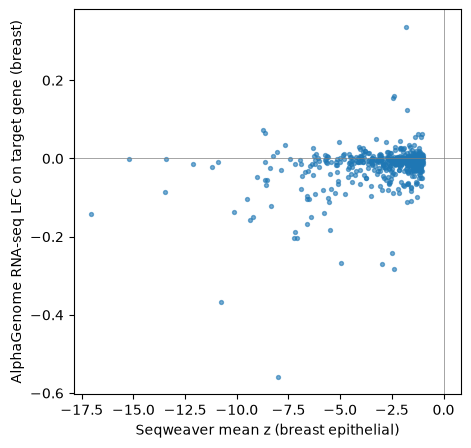

In [12]:
# Predicted RNA-seq log fold change (ALT vs REF) on the variant's own target gene,
# averaged over the breast tracks, next to the Seqweaver mean z-score.
GENE_ALIASES = {'MRE11A': 'MRE11'}  # hg19 name -> GENCODE v46 name
target = CONCORDANT_SNPs[['SNP', 'gene_name', 'mean_z']].assign(
    gene_name=lambda d: d.gene_name.replace(GENE_ALIASES)
)
AG_TARGET = AG_BREAST[AG_BREAST.output_type == 'RNA_SEQ'].merge(
    target, on=['SNP', 'gene_name']
)
COMPARE = (
    AG_TARGET.groupby(['SNP', 'gene_name', 'mean_z'], as_index=False)
    .agg(ag_lfc=('raw_score', 'mean'), ag_quantile=('quantile_score', 'mean'))
    .sort_values('ag_lfc')
)
print(f'{COMPARE.SNP.nunique()} / {len(CONCORDANT_SNPs)} SNPs matched to their target gene')
print('same sign as Seqweaver:', (np.sign(COMPARE.ag_lfc) == np.sign(COMPARE.mean_z)).mean())

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(COMPARE.mean_z, COMPARE.ag_lfc, s=8, alpha=0.6)
ax.axhline(0, color='grey', lw=0.5)
ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel('Seqweaver mean z (breast epithelial)')
ax.set_ylabel('AlphaGenome RNA-seq LFC on target gene (breast)')
COMPARE.head(20)

In [13]:
# Gene annotation (GENCODE v46, hg38) for the transcript track.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gene_annotation.filter_to_longest_transcript(
        gene_annotation.filter_transcript_support_level(
            gene_annotation.filter_protein_coding(gtf), ['1']
        )
    )
)

BREAST_TERMS = [
    'UBERON:0008367',  # breast epithelium
    'CL:0002327',  # mammary epithelial cell
]


def plot_variant(snp, width=2**15):
    """Predict REF vs ALT tracks for one hg19 SNP id and plot `width` bp around it."""
    variant = to_variant(snp)
    interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
    out = dna_model.predict_variant(
        interval=interval,
        variant=variant,
        requested_outputs=[
            dna_client.OutputType.RNA_SEQ,
            dna_client.OutputType.CAGE,
            dna_client.OutputType.DNASE,
        ],
        ontology_terms=BREAST_TERMS,
    )
    components = [
        plot_components.TranscriptAnnotation(
            longest_transcript_extractor.extract(interval)
        )
    ]
    for name in ['rna_seq', 'cage', 'dnase']:
        ref, alt = getattr(out.reference, name), getattr(out.alternate, name)
        label = name.upper() + ': {biosample_name} ({strand})'
        components += [
            plot_components.OverlaidTracks(
                tdata={'REF': ref, 'ALT': alt},
                colors={'REF': 'dimgrey', 'ALT': 'red'},
                ylabel_template=label,
            ),
            plot_components.Tracks(
                tdata=alt - ref, ylabel_template='ALT-REF ' + label, filled=True
            ),
        ]
    return plot_components.plot(
        components,
        interval=variant.reference_interval.resize(width),
        annotations=[plot_components.VariantAnnotation([variant])],
        title=snp,
    )

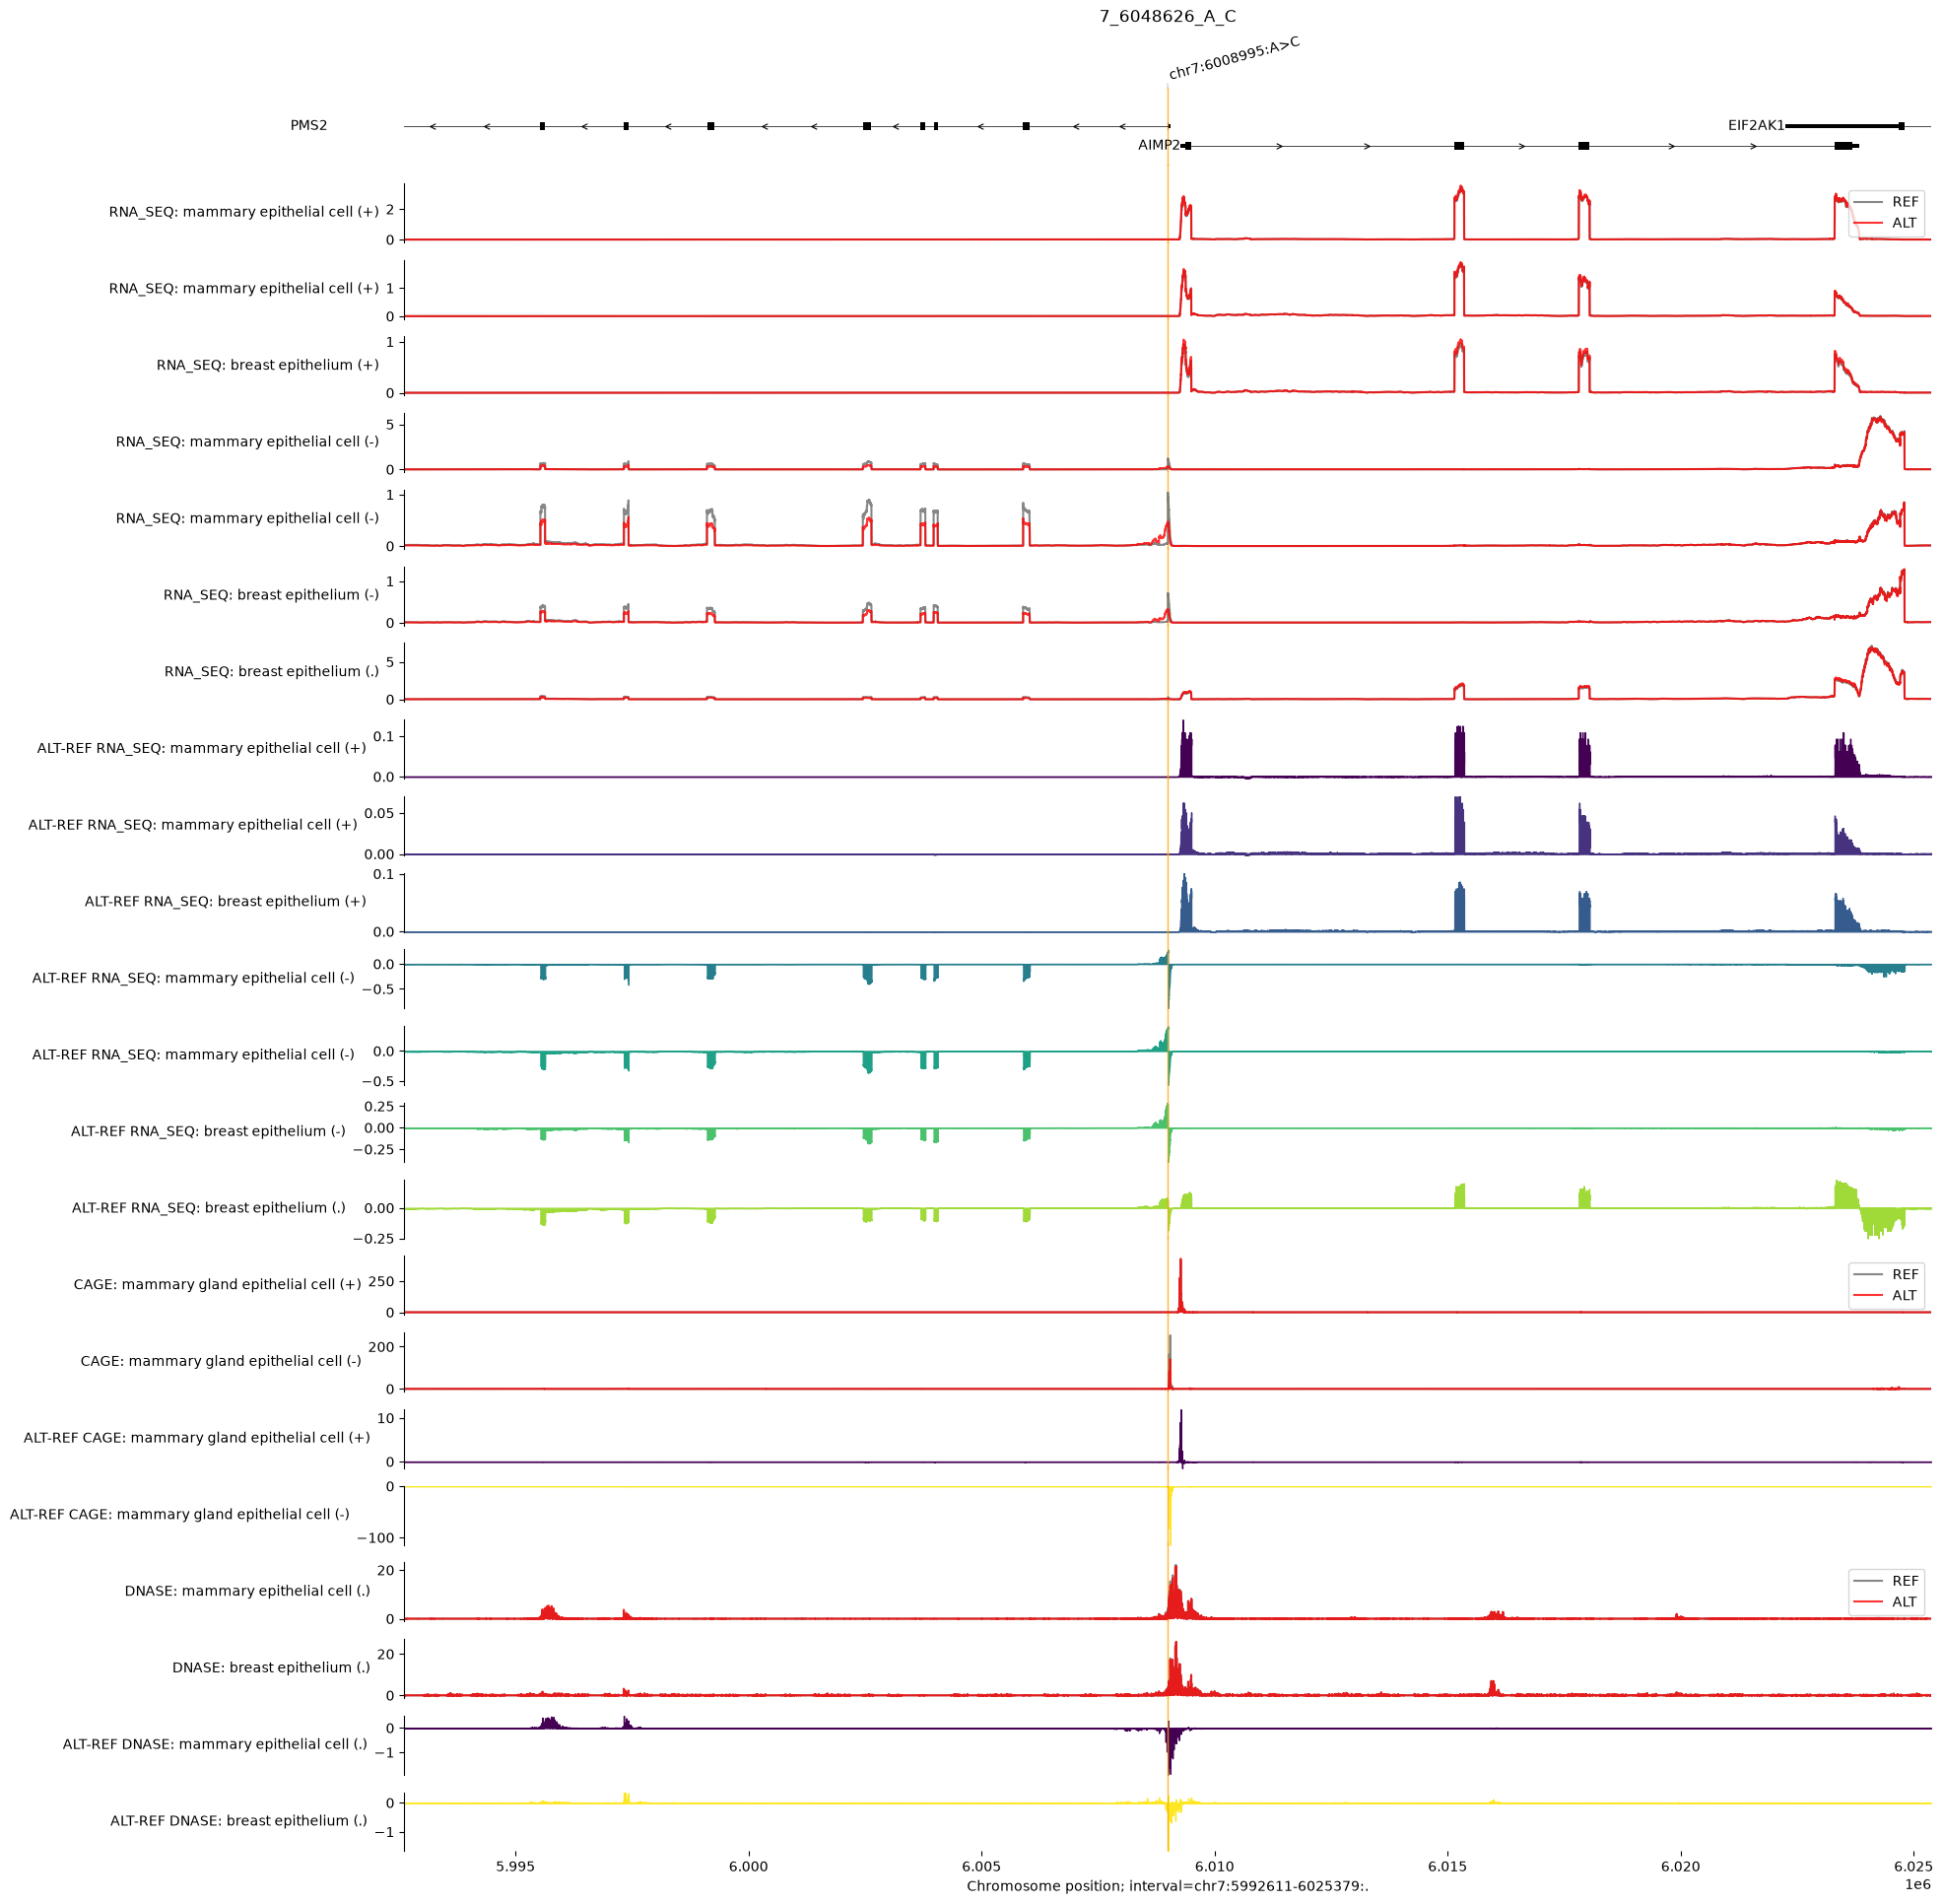

In [14]:
# Strongest predicted down-regulation of the target gene; swap in any SNP id.
fig = plot_variant(COMPARE.SNP.iloc[0])

In [15]:
# Fig. 6a/6b-style plots (AlphaGenome paper, TAL1 example) for the BRIDGES genes.
GENE_ALIASES = {'MRE11A': 'MRE11'}  # hg19 name -> GENCODE v46 name
FIG6_TERM = 'CL:0002327'  # mammary epithelial cell: has RNA-seq, DNase and 10 histone marks


def gene_locus(gene_name, snps, pad=0.05):
    """hg38 interval covering the gene body and the given hg19 SNP ids."""
    g = gtf[
        (gtf.gene_name == GENE_ALIASES.get(gene_name, gene_name))
        & (gtf.Feature == 'gene')
    ].iloc[0]
    positions = [to_variant(s).position for s in snps]
    start, end = min([g.Start, *positions]), max([g.End, *positions])
    margin = int((end - start) * pad)
    return genome.Interval(g.Chromosome, start - margin, end + margin, strand=g.Strand)


def plot_gene_variants(gene_name, n_labels=1):
    """Fig. 6a-style overview: positions of the concordant SNPs along the gene."""
    df = CONCORDANT_SNPs[CONCORDANT_SNPs.gene_name == gene_name].sort_values(
        'max_abs_z', ascending=False
    )
    interval = gene_locus(gene_name, df.SNP)
    # Label only the strongest Seqweaver hit(s) to avoid overplotting.
    labels = [snp if i < n_labels else '' for i, snp in enumerate(df.SNP)]
    return plot_components.plot(
        [
            plot_components.TranscriptAnnotation(
                longest_transcript_extractor.extract(interval)
            )
        ],
        annotations=[
            plot_components.VariantAnnotation(
                [to_variant(s) for s in df.SNP],
                labels=labels,
                use_default_labels=False,
                alpha=0.8,
            )
        ],
        interval=interval,
        title=f'Positions of {len(df)} concordant variants near {gene_name}',
    )


def plot_alt_minus_ref(snp, gene_name=None, interval=None):
    """Fig. 6b-style plot: ALT - REF predictions across modalities for one SNP."""
    if gene_name is None:
        gene_name = CONCORDANT_SNPs.set_index('SNP').gene_name[snp]
    variant = to_variant(snp)
    locus = gene_locus(gene_name, [snp])
    out = dna_model.predict_variant(
        interval=variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB),
        variant=variant,
        requested_outputs={
            dna_client.OutputType.RNA_SEQ,
            dna_client.OutputType.DNASE,
            dna_client.OutputType.CHIP_HISTONE,
        },
        ontology_terms=[FIG6_TERM],
    )

    def diff(name):
        # Keep the gene's strand plus unstranded tracks.
        ref, alt = getattr(out.reference, name), getattr(out.alternate, name)
        if locus.strand == '-':
            return alt.filter_to_nonpositive_strand() - ref.filter_to_nonpositive_strand()
        return alt.filter_to_nonnegative_strand() - ref.filter_to_nonnegative_strand()

    return plot_components.plot(
        [
            plot_components.TranscriptAnnotation(
                longest_transcript_extractor.extract(locus)
            ),
            *[
                plot_components.Tracks(
                    tdata=diff(name),
                    ylabel_template='{biosample_name} ({strand})\n{name}',
                    filled=True,
                )
                for name in ['rna_seq', 'dnase', 'chip_histone']
            ],
        ],
        annotations=[plot_components.VariantAnnotation([variant])],
        interval=interval or locus,
        title=(
            f'ALT - REF predictions in mammary epithelial cells, {gene_name}\n'
            f'{snp} ({variant})'
        ),
    )

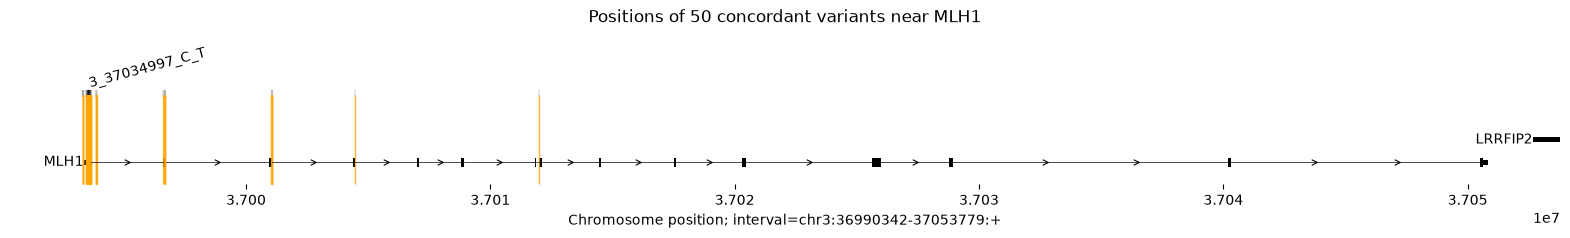

In [16]:
# Fig. 6a-style: where the concordant variants sit along MLH1.
fig = plot_gene_variants('MLH1')
fig.savefig('fig6a_MLH1.png', dpi=200, bbox_inches='tight')

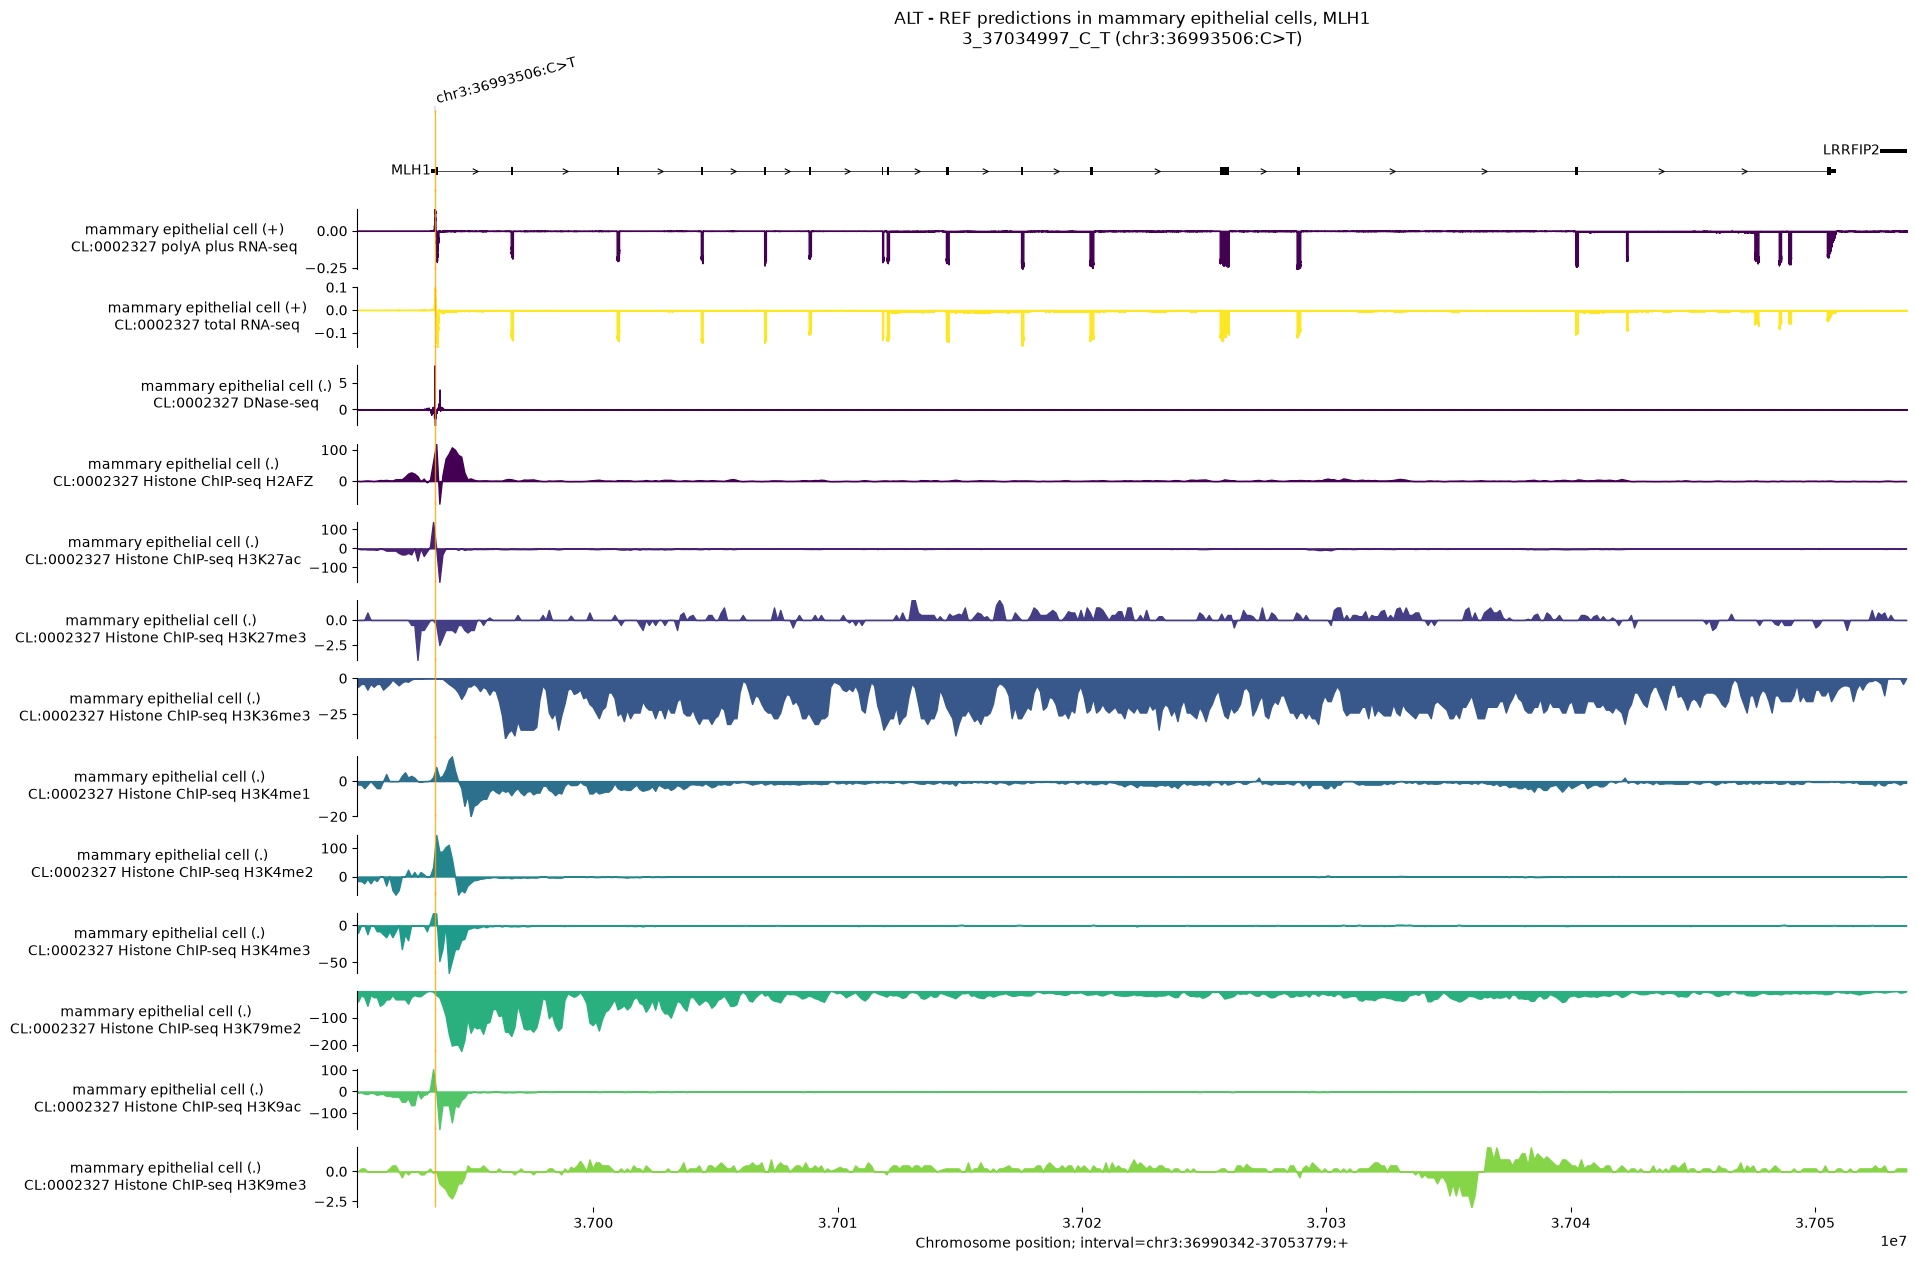

In [17]:
# Fig. 6b-style: ALT - REF across RNA-seq, DNase and histone marks for the top MLH1 hit.
fig = plot_alt_minus_ref('3_37034997_C_T')
fig.savefig('fig6b_3_37034997_C_T.png', dpi=200, bbox_inches='tight')